# 8 — CNN


## Imports


In [1]:
from pathlib import Path
import hashlib
import shutil
import importlib.metadata
import json
import platform
import gc
import random
from time import perf_counter
import numpy as np
import optuna
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import f1_score


c:\Users\Kongkiat\miniconda3\envs\pattern\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Configuration


In [2]:
from pathlib import Path
# ใช้ project root เดียวกัน ไม่ต้อง import โค้ด pipeline จาก program
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'dataset').is_dir() and (p / 'model').is_dir() and (p / 'program').is_dir())
RAW = ROOT / 'dataset/raw/mit-bih-arrhythmia-database-1.0.0'
DATA = ROOT / 'dataset/processed'
ARTIFACTS = ROOT / 'model/artifacts'
REPORTS = ROOT / 'model/reports'
CLASSES = ['N', 'S', 'V', 'F', 'Q']
SYMBOLS = ['NLRej', 'AaJS', 'VE', 'F', '/fQ']
LABEL_MAP = {s: i for i, group in enumerate(SYMBOLS) for s in group}
SEED = 42
PREPROCESSING = {'version': 1, 'fs': 360, 'left': 90, 'right': 162,
                 'band': [0.5, 40], 'order': 4, 'leads': ['MLII', 'V5']}
MODEL = 'cnn'


## Baseline hyperparameters


In [3]:
# ค่าตั้งต้นสำหรับ baseline แก้เฉพาะ cell นี้ได้
BASELINE_PARAMETERS = {
    'channels': [32, 64, 128],
    'kernel': 7,
    'dropout': 0.3,
    'lr': 0.001,
    'weight_decay': 0.0001,
}


## Tuning hyperparameters


In [4]:
TRIALS = 10
# จำนวน trials ต่อ weighted/unweighted และช่วงค้นหา
CHANNEL_OPTIONS = {'small': [16, 32, 64], 'large': [32, 64, 128]}
TUNING_SPACE = {
    'width': {'type': 'categorical', 'choices': list(CHANNEL_OPTIONS)},
    'kernel': {'type': 'categorical', 'choices': [5, 7, 11]},
    'dropout': {'type': 'float', 'low': 0.1, 'high': 0.5},
    'lr': {'type': 'float', 'low': 0.0001, 'high': 0.003, 'log': True},
    'weight_decay': {'type': 'float', 'low': 0.000001, 'high': 0.001, 'log': True},
}


## Training controls


In [5]:
WEIGHTING_OPTIONS = [False, True]
MAX_EPOCHS = 100
EARLY_STOPPING_PATIENCE = 10
BATCH_SIZES = [128, 64, 32]  # ลดตามลำดับเมื่อ GPU memory ไม่พอ


## Artifact helpers


In [6]:
def read_json(path):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f'ไม่พบ {path}; กรุณารัน notebook ขั้นก่อนหน้าก่อน')
    return json.loads(path.read_text(encoding='utf-8'))

def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')

def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()


def reset_directory(path):
    # ล้างเฉพาะโฟลเดอร์ผลลัพธ์ย่อย ห้ามลบ project root หรือโฟลเดอร์รวม
    path = Path(path).resolve()
    roots = [DATA.resolve(), ARTIFACTS.resolve(), REPORTS.resolve()]
    if not any(path != root and path.is_relative_to(root) for root in roots):
        raise ValueError(f'ไม่ใช่โฟลเดอร์ผลลัพธ์ย่อย: {path}')
    if path.is_dir():
        shutil.rmtree(path)
    elif path.exists():
        path.unlink()
    path.mkdir(parents=True, exist_ok=True)
    return path


## Load partition helper


In [7]:
def load_partition(split, *, allow_test=False):
    if split not in ['train', 'validation', 'test']:
        raise ValueError('Unknown partition')
    if split == 'test' and not allow_test:
        raise PermissionError('Test เปิดใน notebook 11 สำหรับประเมินและเลือกผู้ชนะ')
    manifest = read_json(DATA / 'prepared.json')
    folder = DATA / split
    for name in ['metadata.parquet', 'waveforms.npy', 'features.npy']:
        if sha256(folder / name) != manifest['files'][f'{split}/{name}']:
            raise ValueError(f'artifact เปลี่ยน: {split}/{name}')
    meta = pd.read_parquet(folder / 'metadata.parquet')
    waves, x = np.load(folder / 'waveforms.npy'), np.load(folder / 'features.npy')
    if len(meta) != len(waves) or len(meta) != len(x) or meta.beat_id.duplicated().any():
        raise ValueError('beat alignment ไม่ถูกต้อง')
    if not meta.split.eq(split).all() or set(meta.class_id) != set(range(5)):
        raise ValueError('partition หรือ class coverage ไม่ถูกต้อง')
    if not np.array_equal(meta.waveform_index.to_numpy(), np.arange(len(meta))):
        raise ValueError('waveform index ไม่ตรงกับ metadata')
    if waves.shape != (len(meta), 252) or not np.isfinite(waves).all() or not np.isfinite(x).all():
        raise ValueError('ขนาด waveform หรือค่าข้อมูลหลัง preprocessing ไม่ถูกต้อง')
    return {'meta': meta, 'wave': waves, 'x': x, 'y': meta.class_id.to_numpy()}

## Metrics and training weights


In [8]:
def macro_f1(y, predicted):
    return float(f1_score(y, predicted, labels=list(range(5)), average='macro', zero_division=0))

def weights_from_train(y):
    counts = np.bincount(y, minlength=5)
    if (counts == 0).any():
        raise ValueError('Train ต้องมีครบ 5 คลาส')
    return len(y) / (5 * counts)

## Reproducibility


In [9]:
def environment():
    packages = ['numpy', 'pandas', 'scipy', 'scikit-learn', 'wfdb', 'xgboost',
                'torch', 'optuna', 'streamlit', 'pyarrow']
    versions = {}
    for package in packages:
        try:
            versions[package] = importlib.metadata.version(package)
        except importlib.metadata.PackageNotFoundError:
            versions[package] = 'not installed'
    return {'python': platform.python_version(), 'platform': platform.platform(),
            'processor': platform.processor(), 'packages': versions}

def set_seed():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

## Model architecture


In [10]:
class ECGNetwork(nn.Module):
    def __init__(self, kind, channels, kernel=7, hidden=64, dropout=.3):
        super().__init__()
        layers, previous = [], 1
        for width in channels:
            layers += [nn.Conv1d(previous, width, kernel, padding=kernel // 2),
                       nn.BatchNorm1d(width), nn.ReLU(), nn.MaxPool1d(2)]
            previous = width
        self.conv = nn.Sequential(*layers)
        self.kind = kind
        if kind == 'cnn_bilstm':
            self.lstm = nn.LSTM(previous, hidden, batch_first=True, bidirectional=True)
            previous = hidden * 2
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(previous, 5))

    def forward(self, x):
        x = self.conv(x)
        if self.kind == 'cnn_bilstm':
            _, (hidden, _) = self.lstm(x.transpose(1, 2))
            x = torch.cat([hidden[-2], hidden[-1]], dim=1)
        else:
            x = x.mean(dim=2)
        return self.head(x)

def network(kind, parameters):
    return ECGNetwork(kind, parameters['channels'], parameters.get('kernel', 7),
                      parameters.get('hidden', 64), parameters.get('dropout', .3))

## Prediction


In [11]:
def probabilities(model, kind, values, device='cpu', batch_size=128):
    outputs = []
    model.eval()
    with torch.inference_mode():
        for start in range(0, len(values), batch_size):
            batch = torch.as_tensor(values[start:start + batch_size, None, :], device=device)
            outputs.append(model(batch).softmax(dim=1).cpu().numpy())
    return np.concatenate(outputs)

def synchronize(device):
    if str(device).startswith('cuda'):
        torch.cuda.synchronize()

## Training loop and early stopping


In [12]:
def validation_epoch_metrics(model, values, labels, criterion, device, batch_size):
    model.eval()
    predictions, numerator, denominator = [], 0., 0.
    with torch.inference_mode():
        for start in range(0, len(values), batch_size):
            batch = torch.as_tensor(values[start:start + batch_size, None, :], device=device)
            targets = torch.as_tensor(labels[start:start + batch_size], dtype=torch.long, device=device)
            logits = model(batch)
            weight = len(targets) if criterion.weight is None else criterion.weight[targets].sum().item()
            numerator += criterion(logits, targets).item() * weight
            denominator += weight
            predictions.append(logits.argmax(1).cpu().numpy())
    return np.concatenate(predictions), numerator / denominator


# เก็บ checkpoint เมื่อ Validation Macro F1 ดีขึ้น ไม่ใช้ Test และไม่ refit
def _fit_network(kind, parameters, train, validation, weights, folder, device, batch_size, epochs):
    set_seed()
    model = network(kind, parameters).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=parameters['lr'], weight_decay=parameters['weight_decay'])
    criterion = nn.CrossEntropyLoss(weight=None if weights is None else torch.tensor(weights, dtype=torch.float32, device=device))
    ds = TensorDataset(torch.from_numpy(train['wave'][:, None, :]), torch.tensor(train['y'], dtype=torch.long))
    loader = DataLoader(ds, batch_size=batch_size, shuffle=True, num_workers=0,
                        generator=torch.Generator().manual_seed(SEED))
    best, stale, best_epoch = -1., 0, 0
    history = []
    for epoch in range(1, epochs + 1):
        model.train()
        loss_sum, loss_weight_sum = 0., 0.
        train_true, train_predicted = [], []
        for values, labels in loader:
            optimizer.zero_grad(set_to_none=True)
            logits = model(values.to(device))
            targets = labels.to(device)
            loss = criterion(logits, targets)
            loss.backward()
            optimizer.step()
            weight = len(labels) if criterion.weight is None else criterion.weight[targets].sum().item()
            loss_sum += loss.item() * weight
            loss_weight_sum += weight
            train_true.append(labels.numpy())
            train_predicted.append(logits.detach().argmax(1).cpu().numpy())
        prediction, validation_loss = validation_epoch_metrics(
            model, validation['wave'], validation['y'], criterion, device, batch_size)
        score = macro_f1(validation['y'], prediction)
        history.append({'epoch': epoch, 'train_loss': loss_sum / loss_weight_sum,
                        'validation_loss': validation_loss,
                        'train_macro_f1': macro_f1(np.concatenate(train_true), np.concatenate(train_predicted)),
                        'validation_macro_f1': score})
        if score > best:
            best, stale, best_epoch = score, 0, epoch
            # เก็บ epoch ที่ดีที่สุด ไม่ใช้ epoch สุดท้ายโดยอัตโนมัติ
            torch.save({k: v.detach().cpu() for k, v in model.state_dict().items()}, folder / 'model.pt')
        else:
            stale += 1
        if stale >= EARLY_STOPPING_PATIENCE:
            break
    model.load_state_dict(torch.load(folder / 'model.pt', map_location=device, weights_only=True))
    pd.DataFrame(history).to_csv(folder / 'history.csv', index=False)
    return model, best_epoch

## Fit and save one candidate


In [13]:
# Train เท่านั้นที่ปรับน้ำหนักโมเดล; Validation ใช้ให้คะแนนและเลือก checkpoint
def fit_candidate(kind, weighted, parameters, folder, train, validation, *, epochs=None, rounds=None):
    reset_directory(folder)
    set_seed()
    epochs = MAX_EPOCHS if epochs is None else epochs
    is_dl = True
    device = 'cuda' if is_dl and torch.cuda.is_available() else 'cpu'
    if is_dl and device != 'cuda':
        raise RuntimeError('แผนนี้ใช้ GPU สำหรับ DL: ติดตั้ง PyTorch CUDA ก่อนรัน')
    weights = weights_from_train(train['y']) if weighted else None
    started = perf_counter()
    history, best_round, used_batch, oom_batches = ({}, None, None, [])
    for batch_size in BATCH_SIZES:
        try:
            model, best_round = _fit_network(kind, parameters, train, validation, weights, folder, device, batch_size, epochs)
            used_batch = batch_size
            break
        except torch.cuda.OutOfMemoryError:
            oom_batches.append(batch_size)
            gc.collect()
            torch.cuda.empty_cache()
            if batch_size == BATCH_SIZES[-1]:
                raise
    synchronize(device)
    train_seconds = perf_counter() - started
    values = validation['wave'] if is_dl else validation['x']
    proba = probabilities(model, kind, values, device)
    score = macro_f1(validation['y'], proba.argmax(1))
    result = validation['meta'].copy()
    result['predicted'] = proba.argmax(1)
    for i in range(5):
        result[f'score_{i}'] = proba[:, i]
    result.to_parquet(folder / 'validation_predictions.parquet', index=False)
    info = {'kind': kind, 'weighted': weighted, 'seed': SEED, 'parameters': parameters, 'validation_macro_f1': score, 'train_seconds': train_seconds, 'best_epoch_or_round': best_round, 'batch_size': used_batch, 'oom_batch_attempts': oom_batches, 'device': device, 'gpu': torch.cuda.get_device_name(0) if device == 'cuda' else None, 'class_weights': None if weights is None else weights.tolist(), 'prepared_hash': sha256(DATA / 'prepared.json'), 'environment': environment()}
    write_json(folder / 'info.json', info)
    del model
    gc.collect()
    if device == 'cuda':
        torch.cuda.empty_cache()
    return info

## Hyperparameter search space


In [14]:
def search_parameters(trial, kind):
    # ช่วงค้นหาทั้งหมดแก้ได้ใน cell Tuning hyperparameters ด้านบน
    values = {}
    for name, spec in TUNING_SPACE.items():
        if spec['type'] == 'categorical':
            values[name] = trial.suggest_categorical(name, spec['choices'])
        elif spec['type'] == 'float':
            values[name] = trial.suggest_float(name, spec['low'], spec['high'],
                                               log=spec.get('log', False))
        else:
            raise ValueError(f'Unknown parameter type: {spec["type"]}')
    if kind in ['cnn', 'cnn_bilstm']:
        values['channels'] = list(CHANNEL_OPTIONS[values.pop('width')])
    return values


## Load Train and Validation


In [15]:
# ไม่อ่าน Test และไม่แบ่ง inner validation
train = load_partition('train')
validation = load_partition('validation')

## Baseline


In [16]:
# ฝึก baseline ก่อน เพื่อเทียบกับผล tuning โดยใช้ split เดียวกัน
runs = {}
for weighted in WEIGHTING_OPTIONS:
    name = f'{MODEL}_{"weighted" if weighted else "unweighted"}'
    folder = ARTIFACTS / name
    reset_directory(folder)
    baseline = fit_candidate(MODEL, weighted, BASELINE_PARAMETERS, folder / 'baseline', train, validation)
    runs[name] = {'folder': folder, 'weighted': weighted, 'baseline': baseline,
                  'candidates': [('baseline', baseline)], 'tuning_seconds': 0.}

C:\Users\Kongkiat\AppData\Local\Temp\ipykernel_34844\1051304760.py:7: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  targets = torch.as_tensor(labels[start:start + batch_size], dtype=torch.long, device=device)


## Tuning on Validation


In [17]:
# แต่ละ trial ฝึกด้วย hyperparameters ของ trial โดยใช้ seed 42 เดียวกัน
# หลัง tuning เลือก checkpoint ที่มีแล้ว ไม่ฝึกใหม่อีกครั้ง
for name, run in runs.items():
    folder = run['folder']
    # รัน cell นี้ซ้ำได้ เริ่ม trials และคะแนนจาก baseline เดิมใหม่
    run['candidates'] = [('baseline', run['baseline'])]
    for previous in folder.glob('trial_*'):
        reset_directory(previous)
        previous.rmdir()
    (folder / 'selected.json').unlink(missing_ok=True)
    study = optuna.create_study(direction='maximize',
                                sampler=optuna.samplers.TPESampler(seed=SEED))
    def objective(trial):
        run_id = f'trial_{trial.number:02d}'
        params = search_parameters(trial, MODEL)
        try:
            info = fit_candidate(MODEL, run['weighted'], params, folder / run_id, train, validation)
        except Exception as error:
            trial.set_user_attr('failure', f'{type(error).__name__}: {error}')
            write_json(folder / run_id / 'failure.json', {'error': str(error), 'parameters': params})
            raise
        run['candidates'].append((run_id, info))
        return info['validation_macro_f1']
    started = perf_counter()
    try:
        study.optimize(objective, n_trials=TRIALS, catch=(RuntimeError, ValueError), n_jobs=1)
    finally:
        run['tuning_seconds'] = perf_counter() - started
        study.trials_dataframe().to_csv(folder / 'trials.csv', index=False)

[I 2026-10-13 20:14:46,251] A new study created in memory with name: no-name-2427c7d0-5b7c-4399-8c1a-4d38d5c16205
[I 2026-10-13 20:16:45,122] Trial 0 finished with value: 0.5695463737348301 and parameters: {'width': 'large', 'kernel': 5, 'dropout': 0.16239780813448107, 'lr': 0.00012184186502221769, 'weight_decay': 0.0003967605077052988}. Best is trial 0 with value: 0.5695463737348301.
[I 2026-10-13 20:18:49,739] Trial 1 finished with value: 0.5680048653342584 and parameters: {'width': 'large', 'kernel': 7, 'dropout': 0.18493564427131048, 'lr': 0.00018559980846490597, 'weight_decay': 3.549878832196506e-06}. Best is trial 0 with value: 0.5695463737348301.
[I 2026-10-13 20:21:40,208] Trial 2 finished with value: 0.542917160181694 and parameters: {'width': 'large', 'kernel': 11, 'dropout': 0.15579754426081674, 'lr': 0.00027010527749605503, 'weight_decay': 1.2562773503807034e-05}. Best is trial 0 with value: 0.5695463737348301.
[I 2026-10-13 20:25:17,134] Trial 3 finished with value: 0.5661

## Select and save candidates


In [18]:
# เลือก checkpoint ภายใน configuration จาก Validation; notebook 11 เลือกผู้ชนะจาก Test
# baseline_macro_f1 = Validation ของ baseline; validation_macro_f1 = Validation ของ checkpoint ที่เลือก
selected_candidates = []
for name, run in runs.items():
    selected_id, info = max(run['candidates'], key=lambda pair: pair[1]['validation_macro_f1'])
    selected = {'configuration': name, 'candidate': selected_id,
                'validation_macro_f1': info['validation_macro_f1'],
                'baseline_macro_f1': run['baseline']['validation_macro_f1'],
                'tuning_seconds': run['tuning_seconds'], 'prepared_hash': info['prepared_hash']}
    write_json(run['folder'] / 'selected.json', selected)
    selected_candidates.append(selected)
pd.DataFrame(selected_candidates)

,configuration,candidate,validation_macro_f1,baseline_macro_f1,tuning_seconds,prepared_hash
0,cnn_unweighted,trial_04,0.599031,0.579357,1182.282003,1039391cb37a162946ad9ed42d0cca3d0a5e6bc09fe458...
1,cnn_weighted,trial_07,0.627690,0.608639,1652.436604,1039391cb37a162946ad9ed42d0cca3d0a5e6bc09fe458...


## Visualization helpers


In [19]:
def plot_training_curve(folder, info, output):
    history = pd.read_csv(folder / 'history.csv')
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history.epoch, history.train_loss, label='Train (during epoch)')
    if 'validation_loss' in history:
        axes[0].plot(history.epoch, history.validation_loss, label='Validation (end of epoch)')
    else:
        axes[0].text(.02, .02, 'Validation loss unavailable in this saved run', fontsize=8,
                     transform=axes[0].transAxes)
    axes[0].set(xlabel='Epoch', ylabel='Cross-entropy loss', title='Loss (same class weights on both splits)')
    if 'train_macro_f1' in history:
        axes[1].plot(history.epoch, history.train_macro_f1, label='Train (during epoch)')
    axes[1].plot(history.epoch, history.validation_macro_f1, label='Validation (end of epoch)')
    axes[1].set(xlabel='Epoch', ylabel='Macro-F1', ylim=(0, 1.02), title='Macro-F1')
    best_epoch = info.get('best_epoch_or_round')
    for ax in axes:
        if best_epoch is not None:
            ax.axvline(best_epoch, color='#64748b', linestyle='--', label=f'Saved epoch {best_epoch}')
        ax.grid(alpha=.2)
        ax.legend(fontsize=8)
    fig.suptitle(f'{folder.parent.name} | {folder.name}')
    fig.tight_layout()
    fig.savefig(output / 'learning_curve.png', dpi=160)
    return fig


def plot_tuning_progress(folder, selected, output):
    try:
        trials = pd.read_csv(folder / 'trials.csv')
    except pd.errors.EmptyDataError:
        trials = pd.DataFrame(columns=['number', 'value', 'state'])
    complete = trials.loc[trials['state'].eq('COMPLETE') & trials['value'].notna()].sort_values('number')
    fig, ax = plt.subplots(figsize=(8, 4))
    baseline = selected['baseline_macro_f1']
    ax.axhline(baseline, color='#64748b', linestyle='--', label='Baseline Validation Macro-F1')
    if not complete.empty:
        x = complete['number'].to_numpy() + 1
        y = complete['value'].to_numpy()
        ax.scatter(x, y, color='#2563eb', label='Completed trial')
        ax.plot(x, np.maximum.accumulate(np.maximum(y, baseline)), color='#d97706',
                marker='o', label='Best including baseline')
    else:
        ax.text(.5, .5, 'No completed tuning trials', ha='center', transform=ax.transAxes)
    ax.set(xlabel='Trial number', ylabel='Validation Macro-F1', ylim=(0, 1.02),
           title=f"{selected['configuration']} | selected: {selected['candidate']}")
    ax.grid(alpha=.2)
    ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(output / 'tuning_progress.png', dpi=160)
    return fig


## Visualize learning curves and tuning


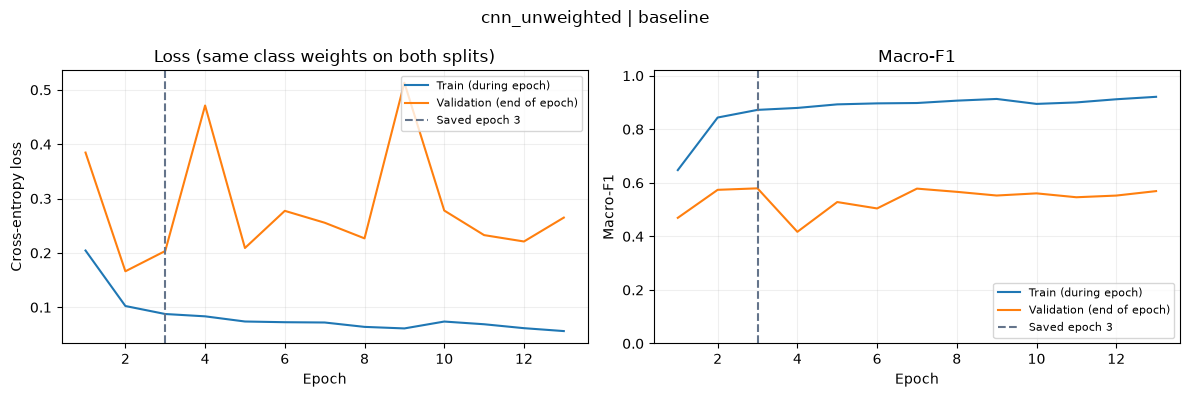

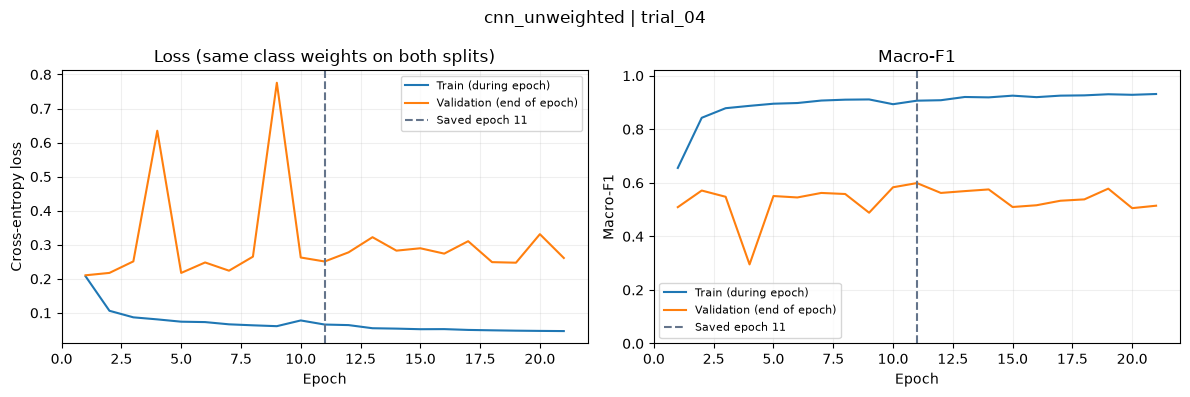

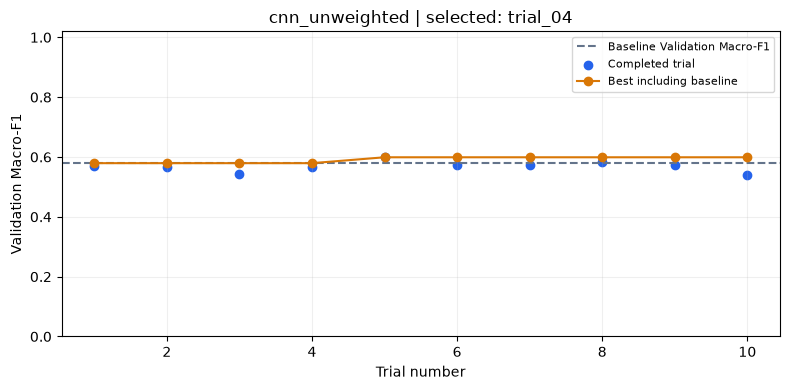

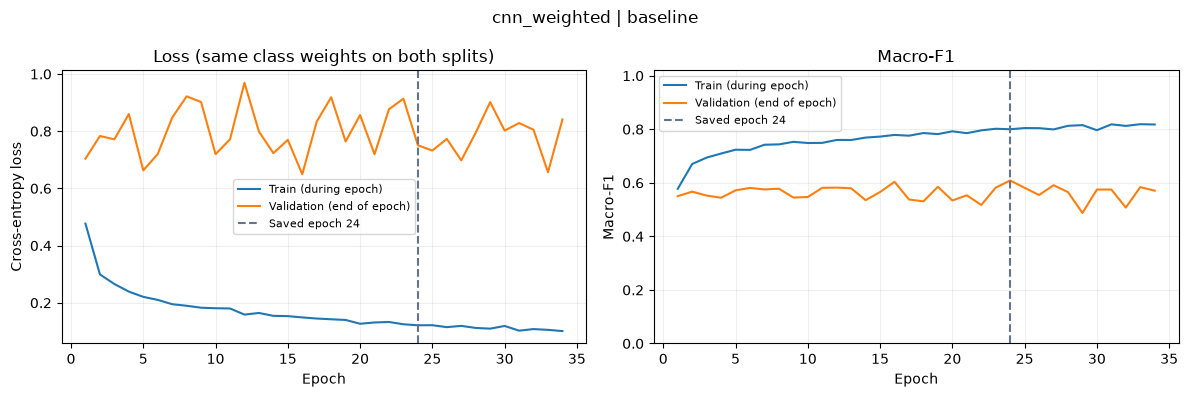

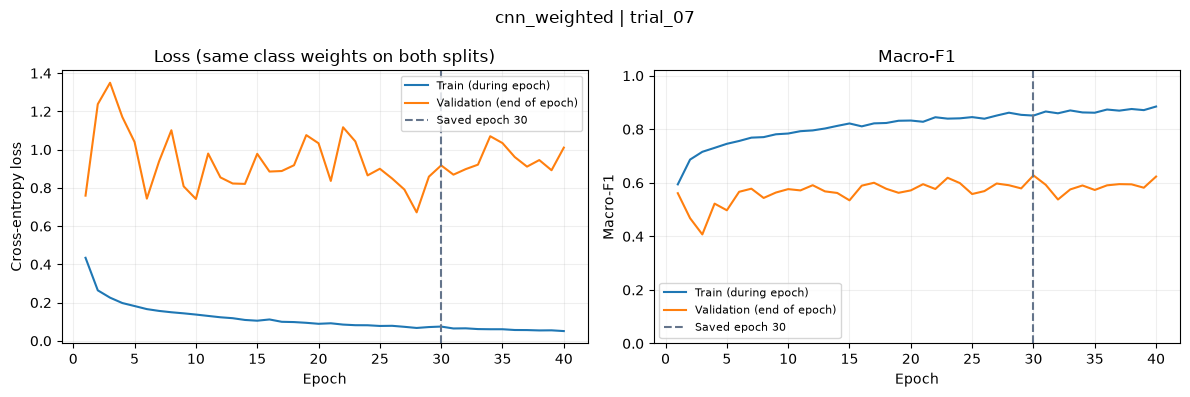

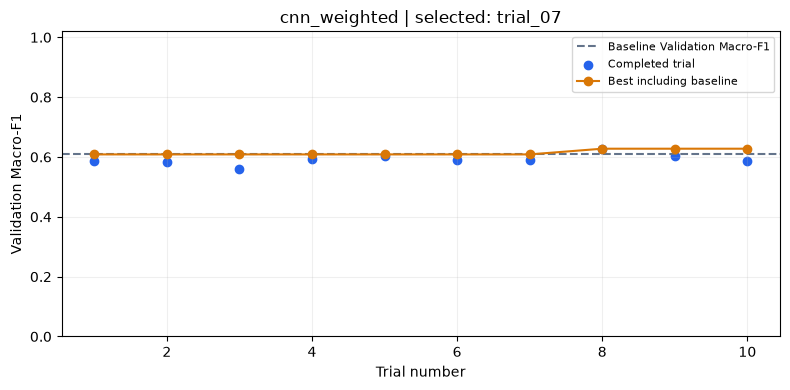

WindowsPath('C:/Users/Kongkiat/Documents/Project/cardiac-arrhythmia-classification/model/reports/training/cnn')

In [20]:
# รัน cells นี้จาก artifacts เดิมได้ หลัง Imports / Configuration / helpers โดยไม่ฝึกใหม่
visual_output = reset_directory(REPORTS / 'training' / MODEL)
for weighted in WEIGHTING_OPTIONS:
    name = f'{MODEL}_{"weighted" if weighted else "unweighted"}'
    folder = ARTIFACTS / name
    selected = read_json(folder / 'selected.json')
    if selected['prepared_hash'] != sha256(DATA / 'prepared.json'):
        raise ValueError(f'{name}: ข้อมูลเปลี่ยน; รัน notebook โมเดลนี้ใหม่')
    output = visual_output / name
    output.mkdir(parents=True, exist_ok=True)
    for candidate in dict.fromkeys(['baseline', selected['candidate']]):
        run = folder / candidate
        run_output = output / candidate
        run_output.mkdir(parents=True, exist_ok=True)
        info = read_json(run / 'info.json')
        fig = plot_training_curve(run, info, run_output)
        plt.show()
        plt.close(fig)
    fig = plot_tuning_progress(folder, selected, output)
    plt.show()
    plt.close(fig)
visual_output


## Final selected hyperparameters


In [21]:
from IPython.display import display

final_parameters = {}
for weighted in WEIGHTING_OPTIONS:
    name = f'{MODEL}_{"weighted" if weighted else "unweighted"}'
    folder = ARTIFACTS / name
    selected = read_json(folder / 'selected.json')
    info = read_json(folder / selected['candidate'] / 'info.json')
    values = {
        'candidate': selected['candidate'],
        'validation_macro_f1': info['validation_macro_f1'],
        **info['parameters'],
        'weighted': info['weighted'],
        'seed': info['seed'],
        'class_weights': (None if info['class_weights'] is None
                          else dict(zip(CLASSES, info['class_weights']))),
    }
    if info['batch_size'] is not None:
        values['batch_size'] = info['batch_size']
    if info['best_epoch_or_round'] is not None:
        key = 'best_epoch' if MODEL in ['cnn', 'cnn_bilstm'] else 'best_boost_round'
        values[key] = info['best_epoch_or_round']
  
    final_parameters[name] = {
        key: value if isinstance(value, str) else repr(value)
        for key, value in values.items()
    }

final_hyperparameters = pd.DataFrame(final_parameters)
final_hyperparameters.index.name = 'Hyperparameter / selection'
with pd.option_context('display.max_rows', None, 'display.max_columns', None,
                       'display.max_colwidth', None):
    display(final_hyperparameters)


,cnn_unweighted,cnn_weighted
Hyperparameter / selection,,
candidate,trial_04,trial_07
validation_macro_f1,0.5990305765558472,0.6276895899910478
kernel,5,11
dropout,0.13906884560255356,0.20853961270955837
lr,0.0010249322216924156,0.0016755052359850296
weight_decay,2.091498132903561e-05,1.1756010900231857e-05
channels,"[32, 64, 128]","[32, 64, 128]"
weighted,False,True
seed,42,42
